# HalfDome halo mass calibration and paper figure

Reproduce the purple RFoF / green Tinker08-calibrated HMF figure using histogram
counts from all 11 released HDF5 catalogs, then apply the mass calibration spline.
The calibration is fitted to released mass pairs and checked on independent
catalogs.

In [1]:
from pathlib import Path
import json
import tempfile
import h5py
import numpy as np
from IPython.display import Image, display
from paper_plot import plot_release
from remapping import MassRemapping, apply_hdf5, validate_pairs

ROOT = Path.cwd()
DATA = ROOT / "data"
OUTPUT = ROOT / "validation"
OUTPUT.mkdir(parents=True, exist_ok=True)
samples = np.load(DATA / "release_samples.npz")
print("Released seeds:", samples["seeds"].tolist())

Released seeds: [100, 102, 104, 106, 108, 110, 112, 114, 116, 118, 120]


## Reproduce the paper HMF figure

Redshift slices are 0–0.05, 1–1.05, 2–2.05, and 3–3.05. Error bars are the
standard deviation over the 11 realizations.
Grey curves use the installed HMF package with the HalfDome cosmology.

findfont: Failed to find font weight bold for cmr10, now using 400.


findfont: Failed to find font weight bold for cmr10, now using 400.


findfont: Failed to find font weight bold for STIXSizeFiveSym, now using 400.


findfont: Failed to find font weight bold for cmmi10, now using 400.


findfont: Failed to find font weight bold for cmsy10, now using 400.


...

findfont: Failed to find font weight bold for cmb10, now using 400.


findfont: Failed to find font weight bold for cmss10, now using 400.


findfont: Failed to find font weight bold for cmex10, now using 400.


findfont: Failed to find font weight bold for cmr10, now using 400.


findfont: Failed to find font weight bold for cmr10, now using 400.


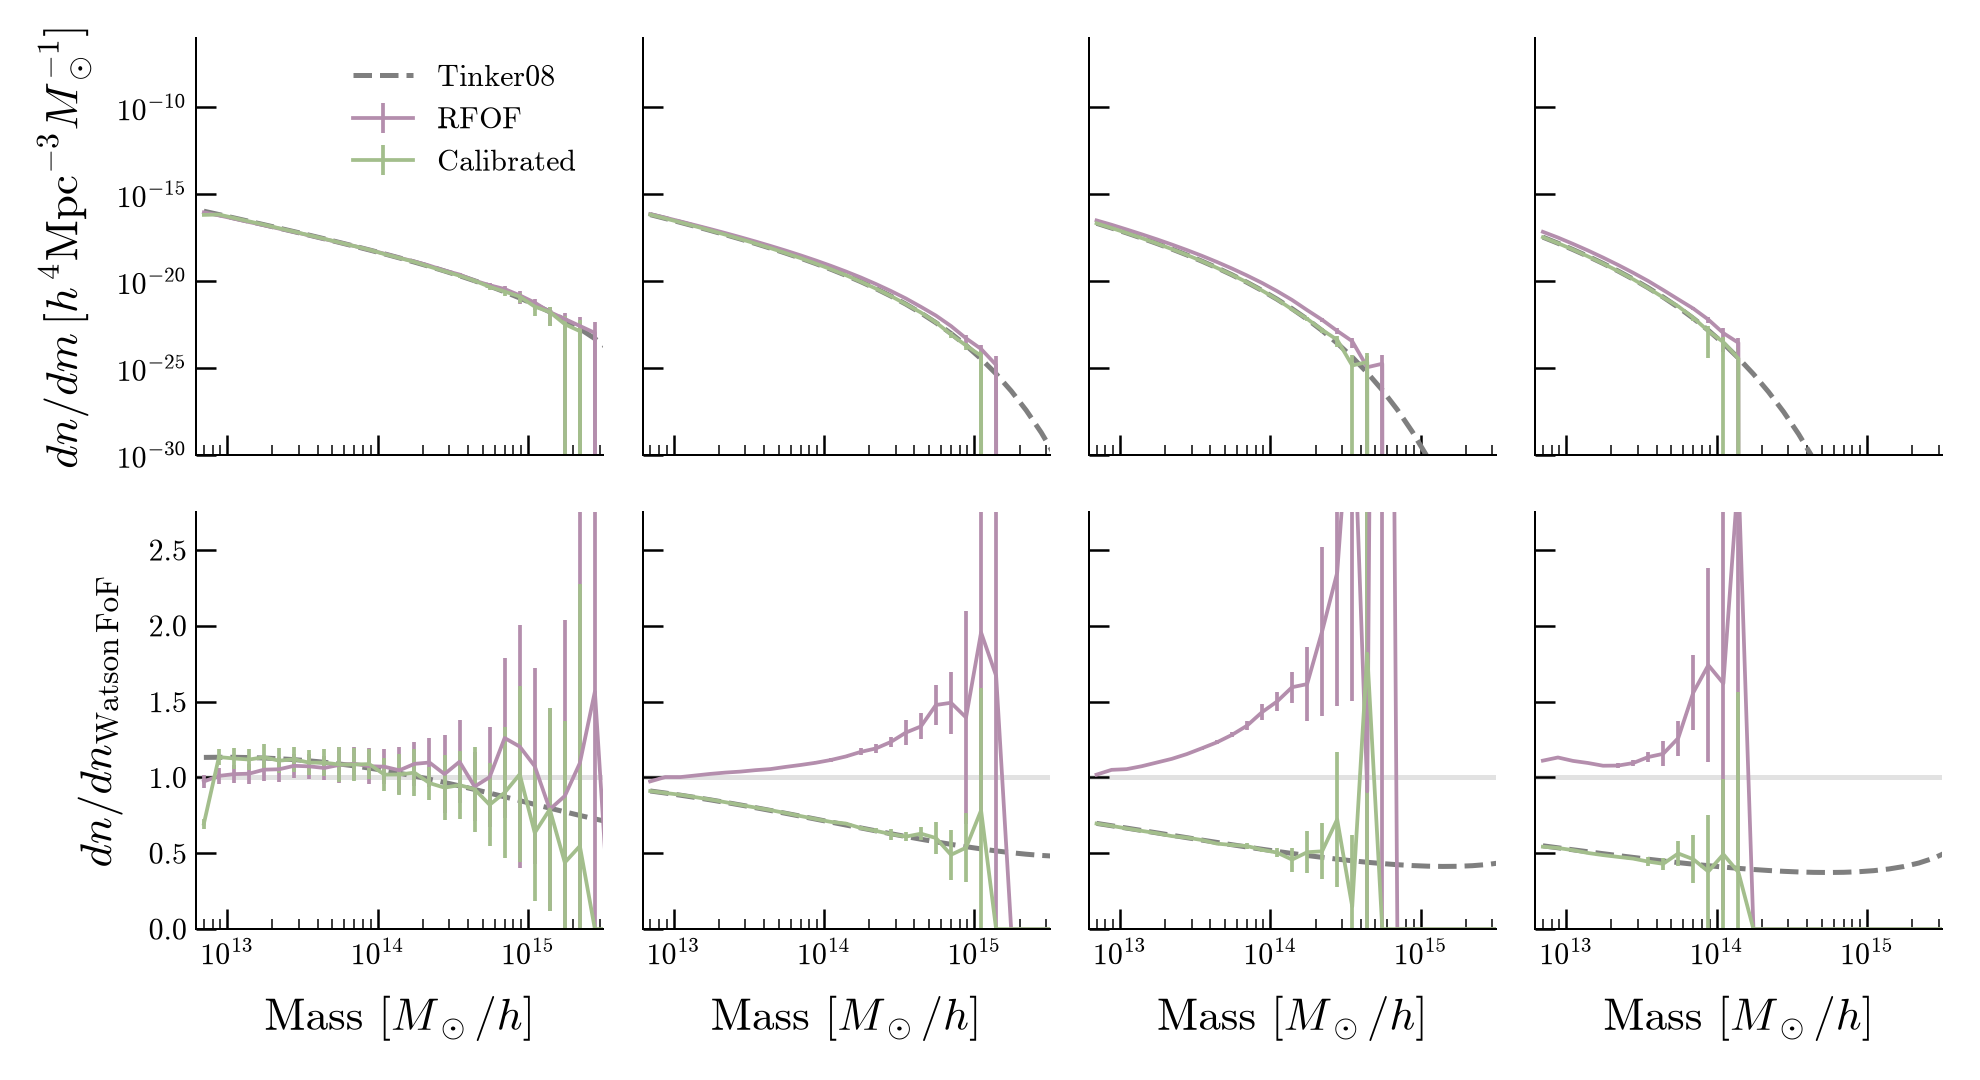

In [2]:
figure = plot_release(DATA / "release_samples.npz", OUTPUT / "reproduced-HMF")
display(Image(filename=str(figure)))

## Apply the mass calibration

The historical formula is `log10_M200m = log10_Mrfof * (1 + correction(z, log10_Mrfof))`.
It is not a multiplicative correction to linear mass. Training excludes seed 104;
the following report uses its independent released mass pairs. The samples are
stratified in mass and redshift and therefore emphasize rare massive halos.

The default call rejects masses above the calibrated range. Setting
`allow_extrapolation=True` permits the regularized continuation and boundary
clamping outside that validated range.

In [3]:
mapping = MassRemapping.load(DATA / "recovered-grid")
final_validation = np.load(DATA / "release_final_validation.npz")
report = validate_pairs(mapping, final_validation["sample_104"])
print("Final independent check: seed 104")
print(json.dumps(report, indent=2))

Final independent check: seed 104
{
  "rows": 76980,
  "median_absolute_relative_mass_error": 4.090212778241044e-15,
  "p99_absolute_relative_mass_error": 1.793341521997546e-11,
  "p999_absolute_relative_mass_error": 7.245900860504599e-10,
  "max_absolute_relative_mass_error": 0.0021050629953610948,
  "worst_input": [
    3.661386489868164,
    13.936741828918457
  ],
  "supported_rows": 76810,
  "supported_fraction": 0.9977916341906988,
  "supported_max_absolute_relative_mass_error": 4.741177863663349e-06
}


In [4]:
# A small independent example within the supported mass range.
example = samples["sample_102"]
example = example[example[:, 1] < 13.3][:20]
predicted = mapping.log10_m200m(example[:, 0], example[:, 1])
relative_error = np.expm1(np.log(10) * (predicted - example[:, 2]))
print("Maximum relative mass error in example:", np.max(np.abs(relative_error)))

Maximum relative mass error in example: 2.0451063891205386e-14


## Convert to M200c

The July 2024 recipe converts calibrated M200m with an NFW profile and the
Bhattacharya13 concentration relation. A bundled table reproduces that recipe
without requiring CCL at runtime. This preserves the released numeric mass
convention (no h rescaling at the historical CCL interface).

Seed 104 supplies a separate check against the released M200c column. The
conversion-only report isolates this new step; the full-chain report also
includes the recovered RFoF calibration error.

In [5]:
from scripts.validate_m200c import validate
from mass_definition import released_log10_m200c

m200c_samples = np.load(DATA / "m200c-samples/release_samples.npz")
print(json.dumps(validate(mapping, m200c_samples["sample_104"]), indent=2))

# Use the actual float32 catalog redshift convention.
z_example = example[:, 0].astype(np.float32)
predicted_c = mapping.log10_m200c(z_example, example[:, 1])
np.testing.assert_allclose(predicted_c, released_log10_m200c(z_example, predicted))
print("M200c / M200m:", 10**(predicted_c - predicted))

{
  "conversion_only": {
    "rows": 76980,
    "supported_rows": 76980,
    "supported_fraction": 1.0,
    "median_absolute_relative_mass_error": 4.787231315790922e-07,
    "p99_absolute_relative_mass_error": 1.9025916147953805e-06,
    "p999_absolute_relative_mass_error": 2.303205828463089e-06,
    "max_absolute_relative_mass_error": 2.468158680986204e-06,
    "supported_max_absolute_relative_mass_error": 2.468158680986204e-06
  },
  "rfof_to_m200c": {
    "rows": 76980,
    "supported_rows": 76810,
    "supported_fraction": 0.9977916341906988,
    "median_absolute_relative_mass_error": 4.787794885488762e-07,
    "p99_absolute_relative_mass_error": 1.907766040970527e-06,
    "p999_absolute_relative_mass_error": 2.3281026772225173e-06,
    "max_absolute_relative_mass_error": 0.0021045182321429404,
    "supported_max_absolute_relative_mass_error": 4.268883602935688e-06
  }
}
M200c / M200m: [0.74285025 0.73408235 0.74404157 0.74596181 0.74187942 0.74187976
 0.74151    0.74350214 0.74129

## Write an aligned HDF5 mass sidecar

This demonstration uses a temporary 20-row catalog. Real inputs need `redshift`
and `log10_m_rfof` (or the historical `log10_m`) in the same row order.
The output is a new HDF5 file containing `halo_mass_m200m` and `halo_mass_m200c` in solar masses/h,
plus source, units, mapping provenance, and row-alignment attributes. Existing
catalogs are never opened for writing.

In [6]:
with tempfile.TemporaryDirectory(prefix="halfdome-example-") as temporary:
    source = Path(temporary) / "input.h5"
    destination = Path(temporary) / "both-masses.h5"
    with h5py.File(source, "w") as f:
        f["redshift"] = z_example
        f["log10_m_rfof"] = example[:, 1]
    apply_hdf5(mapping, source, destination, chunk_size=7, mass_definition="both")
    with h5py.File(destination, "r") as f:
        np.testing.assert_allclose(f["halo_mass_m200m"][:], 10**predicted)
        np.testing.assert_allclose(f["halo_mass_m200c"][:], 10**predicted_c)
        print("Sidecar rows:", len(f["halo_mass_m200m"]))
        print("Units:", f.attrs["units"])

Sidecar rows: 20
Units: Msun/h


The README records commands, data provenance, and the validated calibration
range. Both M200m and M200c are available; the paper HMF figure above retains
its original M200m definition.